# Ingeniería de características para la inversión clásica

**Equipo 39 · Proyecto Integrador MNA**

Esta sección prepara características para estimar propiedades físicas de vigas MEMS con el eigensolver del proyecto. El análisis de espectro y formas modales usa datos sintéticos M0 y M1, porque el conjunto real del Brazo 1 solo contiene la frecuencia fundamental por viga.

**En tres frases:** los cocientes entre frecuencias reducen la escala común asociada al módulo de Young; la varianza y la correlación ayudan a evaluar qué observaciones aportan información repetida o cambiante; la información de Fisher y el PCA cuantifican, respectivamente, sensibilidad local a parámetros y dimensión de las desviaciones modales.

### Contenido

1. Características espectrales
2. Filtrado por varianza
3. Correlación entre observaciones
4. Selección de ubicación y modos con Fisher
5. Extracción con PCA
6. Alcance y conclusión

## 1. Características espectrales

Para cada escenario calculamos $R_2=\omega_2/\omega_1$ y $R_3=\omega_3/\omega_1$. En ausencia de carga axial, al fijar los grupos adimensionales del soporte, un cambio de $E$ multiplica todas las frecuencias por el mismo factor y se cancela en los cocientes. La flexibilidad del anclaje cambia de forma distinta los modos y puede cambiar los cocientes.

La comparación usa el barrido M1 de seis severidades y el control M0, con geometría de voladizo de 300 µm. Estos cocientes son características del experimento sintético: el Brazo 1 del NIST solo reporta la frecuencia fundamental.

In [1]:
import sys
from pathlib import Path

RAIZ = next(
    p.resolve()
    for p in (Path.cwd(), *Path.cwd().resolve().parents)
    if (p / "src" / "pinn_mems").is_dir()
)
sys.path.insert(0, str(RAIZ / "src"))

from dataclasses import replace

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from pinn_mems import Soporte, Viga, resolver_modos
from pinn_mems.colocacion import cota_cramer_rao, fisher, puntos
from pinn_mems.ingenieria_caracteristicas import (
    cocientes_frecuencia,
    direcciones_fisher,
    matriz_correlacion,
    pca_svd,
    seleccionar_puntos_varianza,
    varianza_formas,
)

plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e6e6e3",
    "figure.dpi": 110,
})
COLORES = ["#2a78d6", "#eb6834", "#1baf7a"]
CALIBRACION = pd.read_csv(RAIZ / "datos/sinteticos/calibracion.csv")
VIGA = Viga(E=70e9, L=300e-6, b=28e-6, h=2.743e-6, rho=2200.0)

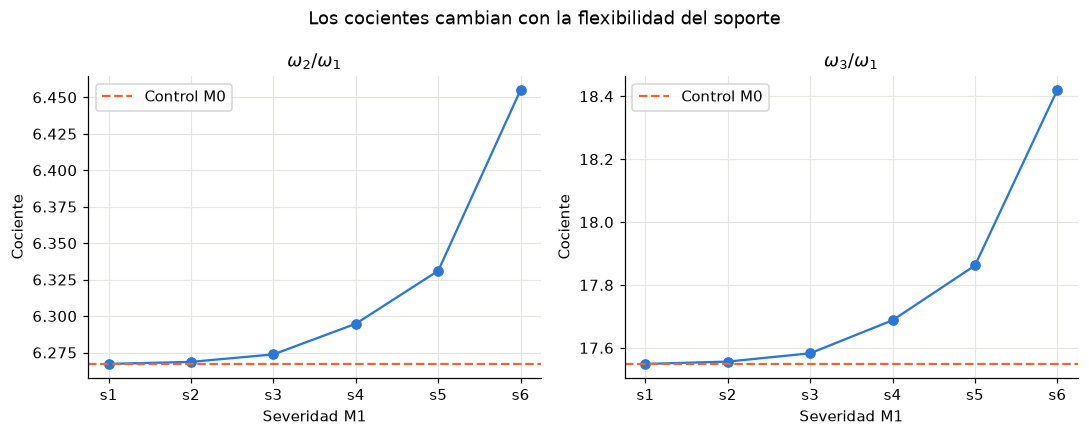

Variación máxima de los cocientes al cambiar E con soporte adimensional fijo: 3.55e-15


,nivel,kappa_theta,omega2/omega1,omega3/omega1
0,s1,396.1235,6.26716,17.54890
1,s2,156.1204,6.26858,17.55633
2,s3,76.1171,6.27370,17.58277
3,s4,36.1109,6.29474,17.68783
4,s5,22.7713,6.33106,17.86190
5,s6,12.0921,6.45518,18.42060


In [2]:
m1 = CALIBRACION[
    (CALIBRACION["generador"] == "M1")
    & (CALIBRACION["estructura"] == "voladizo")
    & CALIBRACION["nivel"].str.fullmatch(r"s[1-6]")
].copy()
m1["orden"] = m1["nivel"].str.extract(r"s(\d+)").astype(int)
m1 = m1.sort_values("orden").reset_index(drop=True)

filas = []
for fila in m1.itertuples():
    modos = resolver_modos(
        VIGA, "voladizo", Soporte(kappa_theta=float(fila.kappa_theta)), n_modos=3
    )
    razones = cocientes_frecuencia(modos.omega)
    filas.append({
        "nivel": fila.nivel,
        "kappa_theta": fila.kappa_theta,
        "omega2/omega1": razones[0],
        "omega3/omega1": razones[1],
    })
tabla_razones = pd.DataFrame(filas)

control = resolver_modos(VIGA, "voladizo", n_modos=3)
razon_m0 = cocientes_frecuencia(control.omega)
fig, ejes = plt.subplots(1, 2, figsize=(10, 4))
for ax, columna, titulo, base in zip(
    ejes,
    ["omega2/omega1", "omega3/omega1"],
    [r"$\omega_2/\omega_1$", r"$\omega_3/\omega_1$"],
    razon_m0,
):
    ax.plot(tabla_razones["nivel"], tabla_razones[columna], "o-", color=COLORES[0])
    ax.axhline(base, color=COLORES[1], linestyle="--", label="Control M0")
    ax.set(title=titulo, xlabel="Severidad M1", ylabel="Cociente")
    ax.legend()
fig.suptitle("Los cocientes cambian con la flexibilidad del soporte")
fig.tight_layout()
plt.show()

# Verificación: al cambiar E con kappa_theta adimensional fijo, los cocientes no cambian.
s3 = float(m1.loc[m1["nivel"] == "s3", "kappa_theta"].iloc[0])
razones_por_E = np.stack([
    cocientes_frecuencia(
        resolver_modos(
            replace(VIGA, E=E),
            "voladizo",
            Soporte(kappa_theta=s3),
            n_modos=3,
        ).omega
    )
    for E in (35e9, 70e9, 105e9)
])
assert np.allclose(razones_por_E, razones_por_E[0], rtol=1e-9, atol=1e-12)
assert not np.allclose(tabla_razones.iloc[0, 2:].to_numpy(dtype=float), tabla_razones.iloc[-1, 2:].to_numpy(dtype=float))
print("Variación máxima de los cocientes al cambiar E con soporte adimensional fijo:",
      f"{np.max(np.abs(razones_por_E - razones_por_E[0])):.2e}")
display(tabla_razones.round(5))

## 2. Filtrado por varianza

Comparamos las formas modales de M1 entre s1 y s6 en 101 posiciones adimensionales. Para cada modo y posición calculamos la varianza entre severidades. Usamos como regla exploratoria conservar puntos cuya varianza sea al menos el 1 % del máximo de ese modo; mostramos también 0.5 % y 2 % para comprobar cuánto depende la selección del umbral.

La varianza mide cuánto cambia una observación en este barrido, pero no equivale por sí sola a información sobre todos los parámetros. La sensibilidad local se contrasta más adelante con Fisher.

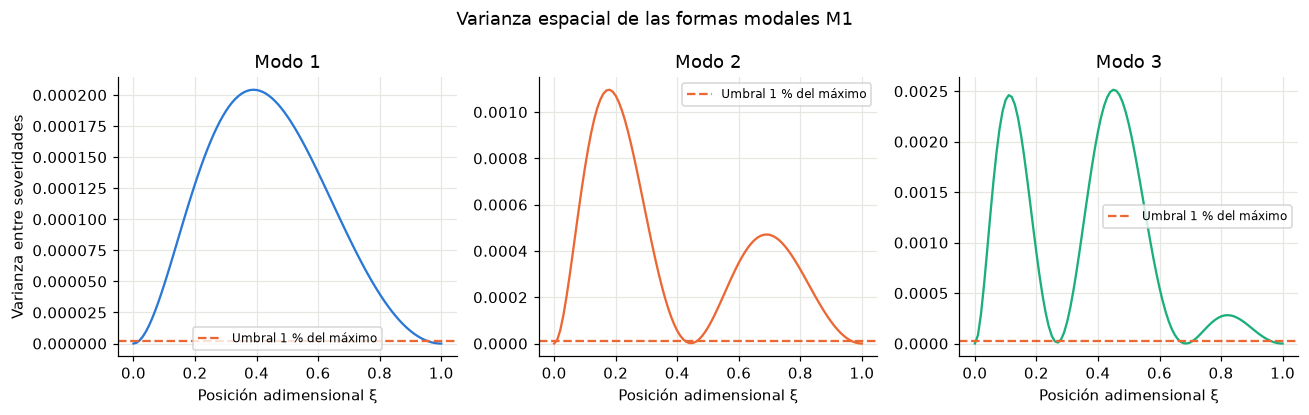

,Umbral relativo al máximo,Puntos modo 1,Puntos modo 2,Puntos modo 3
0,0.5 %,95,95,93
1,1 %,94,92,90
2,2 %,91,88,85


In [3]:
xi = np.linspace(0.0, 1.0, 101)
formas_m1 = np.stack([
    resolver_modos(
        VIGA, "voladizo", Soporte(kappa_theta=float(fila.kappa_theta)), n_modos=3
    ).forma(xi)
    for fila in m1.itertuples()
])
var_formas = varianza_formas(formas_m1)

fig, ejes = plt.subplots(1, 3, figsize=(12, 3.8), sharex=True)
for modo, ax in enumerate(ejes):
    ax.plot(xi, var_formas[modo], color=COLORES[modo])
    ax.axhline(0.01 * var_formas[modo].max(), color=COLORES[1], linestyle="--",
               label="Umbral 1 % del máximo")
    ax.set(title=f"Modo {modo + 1}", xlabel="Posición adimensional ξ")
    if modo == 0:
        ax.set_ylabel("Varianza entre severidades")
    ax.legend(fontsize=8)
fig.suptitle("Varianza espacial de las formas modales M1")
fig.tight_layout()
plt.show()

resumen_umbral = []
for umbral in (0.005, 0.01, 0.02):
    mascara = seleccionar_puntos_varianza(var_formas, fraccion_max=umbral)
    resumen_umbral.append({
        "Umbral relativo al máximo": f"{100 * umbral:g} %",
        **{f"Puntos modo {i + 1}": int(mascara[i].sum()) for i in range(3)},
    })
display(pd.DataFrame(resumen_umbral))

## 3. Correlación entre observaciones

El grupo sintético $k=3$ contiene un voladizo de 300 µm, una viga biempotrada de 300 µm y un voladizo de 200 µm. Se conserva el mismo anclaje físico al cambiar estructura y longitud: la rigidez adimensional del voladizo corto escala con $L$.

La matriz de correlación describe redundancia lineal a través de las seis severidades calibradas. Es un diagnóstico del diseño sintético, con solo seis niveles; por eso no se usa como regla automática para descartar variables.

/tmp/ipykernel_30647/1943963193.py:41: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


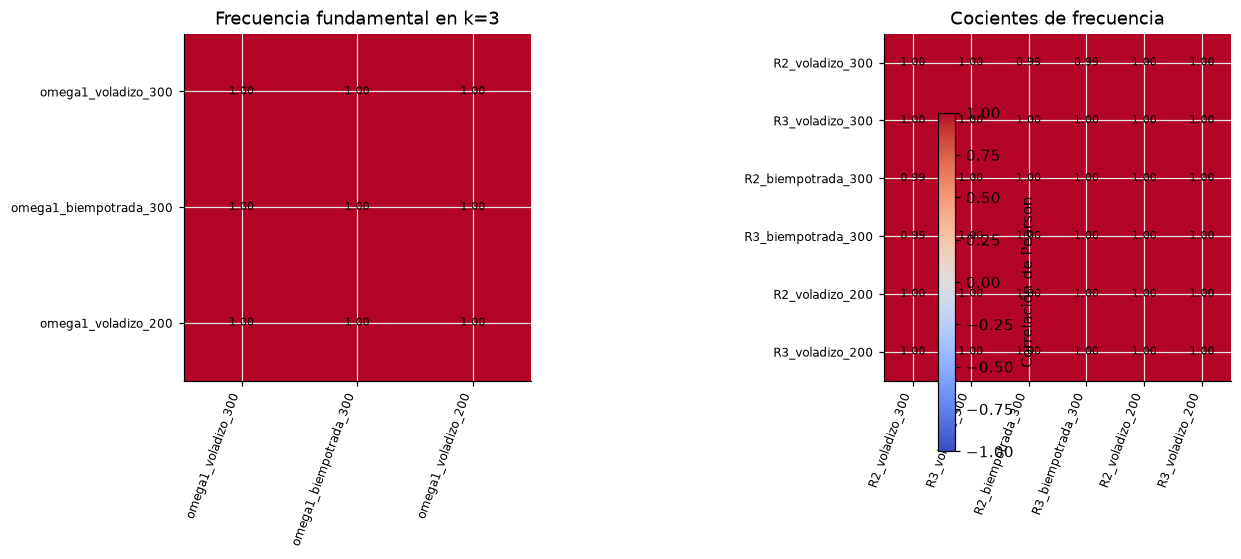

,omega1_voladizo_300,omega1_biempotrada_300,omega1_voladizo_200
omega1_voladizo_300,1.000,0.998,1.000
omega1_biempotrada_300,0.998,1.000,0.999
omega1_voladizo_200,1.000,0.999,1.000


In [4]:
registros = []
for fila in m1.itertuples():
    k300 = float(fila.kappa_theta)
    vigas = [
        ("voladizo 300", replace(VIGA, L=300e-6, sigma0=0.0), "voladizo", k300),
        ("biempotrada 300", replace(VIGA, L=300e-6, sigma0=-5e6), "biempotrada", k300),
        ("voladizo 200", replace(VIGA, L=200e-6, sigma0=0.0), "voladizo", k300 * 200 / 300),
    ]
    registro = {"severidad": fila.nivel}
    for nombre, viga, estructura, kappa in vigas:
        omega = resolver_modos(
            viga, estructura, Soporte(kappa_theta=kappa), n_modos=3
        ).omega
        prefijo = nombre.replace(" ", "_")
        for i, valor in enumerate(omega, start=1):
            registro[f"omega{i}_{prefijo}"] = valor
        razones = cocientes_frecuencia(omega)
        registro[f"R2_{prefijo}"] = razones[0]
        registro[f"R3_{prefijo}"] = razones[1]
    registros.append(registro)

grupo_k3 = pd.DataFrame(registros).set_index("severidad")
nombres_omega1 = [c for c in grupo_k3.columns if c.startswith("omega1_")]
nombres_razones = [c for c in grupo_k3.columns if c.startswith(("R2_", "R3_"))]
corr_omega1 = matriz_correlacion(grupo_k3[nombres_omega1].to_numpy())
corr_razones = matriz_correlacion(grupo_k3[nombres_razones].to_numpy())

fig, ejes = plt.subplots(1, 2, figsize=(13, 5))
for ax, corr, nombres, titulo in [
    (ejes[0], corr_omega1, nombres_omega1, "Frecuencia fundamental en k=3"),
    (ejes[1], corr_razones, nombres_razones, "Cocientes de frecuencia"),
]:
    imagen = ax.imshow(corr, vmin=-1, vmax=1, cmap="coolwarm")
    ax.set_xticks(range(len(nombres)), nombres, rotation=70, ha="right", fontsize=8)
    ax.set_yticks(range(len(nombres)), nombres, fontsize=8)
    ax.set_title(titulo)
    for i in range(len(nombres)):
        for j in range(len(nombres)):
            ax.text(j, i, f"{corr[i, j]:.2f}", ha="center", va="center", fontsize=7)
fig.colorbar(imagen, ax=ejes, label="Correlación de Pearson", shrink=0.8)
fig.tight_layout()
plt.show()
display(grupo_k3[nombres_omega1].corr().round(3))

## 4. Selección de ubicación y modos con Fisher

La matriz de Fisher aproxima cuánta información local aportan las frecuencias y formas para los parámetros del modelo. Comparamos tres ubicaciones de 15 puntos, con uno y tres modos, en s3. El supuesto de ruido es 2 % relativo a la amplitud modal y 0.03 % relativo en frecuencia.

La cota de Cramér–Rao es una aproximación local bajo esos supuestos; no es una medición del error real de un ajuste ni cubre aquí todos los parámetros del proyecto.

,Modos,Ubicación,Cota relativa E (%),Cota relativa κθ (%)
0,1,uniforme,5.11,102.41
1,1,anclaje,5.60,112.36
2,1,punta,6.10,122.29
3,3,uniforme,0.47,10.26
4,3,anclaje,0.47,10.20
5,3,punta,0.49,10.63


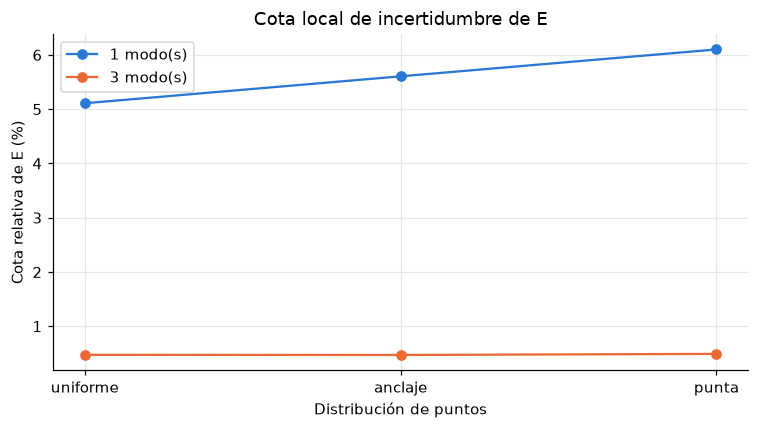

In [5]:
soporte_s3 = Soporte(kappa_theta=s3)
resultados_fisher = []
for n_modos in (1, 3):
    for esquema in ("uniforme", "anclaje", "punta"):
        F = fisher(
            VIGA, "voladizo", soporte_s3, puntos(esquema, 15), n_modos=n_modos
        )
        cota = cota_cramer_rao(F)
        resultados_fisher.append({
            "Modos": n_modos,
            "Ubicación": esquema,
            "Cota relativa E (%)": 100 * cota[0],
            "Cota relativa κθ (%)": 100 * cota[1],
        })
tabla_fisher = pd.DataFrame(resultados_fisher)
display(tabla_fisher.round(2))

fig, ax = plt.subplots(figsize=(7, 4))
for n_modos, color in zip((1, 3), COLORES[:2]):
    parte = tabla_fisher[tabla_fisher["Modos"] == n_modos]
    ax.plot(parte["Ubicación"], parte["Cota relativa E (%)"], "o-",
            color=color, label=f"{n_modos} modo(s)")
ax.set(xlabel="Distribución de puntos", ylabel="Cota relativa de E (%)",
       title="Cota local de incertidumbre de E")
ax.legend()
fig.tight_layout()
plt.show()

## 5. Extracción con PCA

Alineamos y normalizamos las formas modales con la convención determinista del eigensolver. Restamos, modo por modo, la forma M0 de la forma M1 para cada severidad. El PCA resume las direcciones espaciales dominantes de esa desviación; retenemos el menor número de componentes que explica al menos 95 % de su variación en este barrido.

Este resultado caracteriza los datos sintéticos usados para construir la base. No demuestra por sí solo que una base reducida mejore la estimación de parámetros: eso se debe comprobar después en la fase de modelado.

Componentes para explicar al menos 95 %: 2


,Componente,Varianza explicada (%),Acumulada (%)
0,1,72.72,72.72
1,2,22.74,95.46
2,3,4.53,100.00
3,4,0.00,100.00
4,5,0.00,100.00
5,6,0.00,100.00
6,7,0.00,100.00
7,8,0.00,100.00
8,9,0.00,100.00
9,10,0.00,100.00


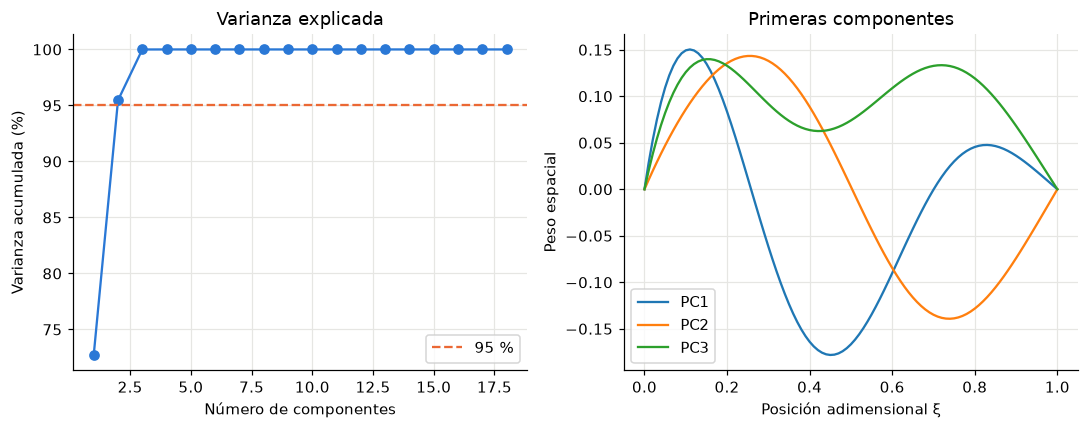

In [6]:
formas_m0 = control.forma(xi)
desviaciones = (formas_m1 - formas_m0[None, :, :]).reshape(-1, len(xi))
pca = pca_svd(desviaciones, varianza_objetivo=0.95)

print("Componentes para explicar al menos 95 %:", pca.n_componentes_objetivo)
display(pd.DataFrame({
    "Componente": np.arange(1, len(pca.varianza_explicada) + 1),
    "Varianza explicada (%)": 100 * pca.varianza_explicada,
    "Acumulada (%)": 100 * pca.varianza_acumulada,
}).round(2))

fig, ejes = plt.subplots(1, 2, figsize=(10, 4))
ejes[0].plot(
    np.arange(1, len(pca.varianza_acumulada) + 1),
    100 * pca.varianza_acumulada, "o-", color=COLORES[0],
)
ejes[0].axhline(95, color=COLORES[1], linestyle="--", label="95 %")
ejes[0].set(xlabel="Número de componentes", ylabel="Varianza acumulada (%)",
            title="Varianza explicada")
ejes[0].legend()
for i in range(min(3, len(pca.componentes))):
    ejes[1].plot(xi, pca.componentes[i], label=f"PC{i + 1}")
ejes[1].set(xlabel="Posición adimensional ξ", ylabel="Peso espacial",
            title="Primeras componentes")
ejes[1].legend()
fig.tight_layout()
plt.show()

### Combinaciones de parámetros bien y mal determinadas

El PCA también se aplica a la matriz de Fisher: sus vectores propios son combinaciones de $\ln E$ y $\ln \kappa_\theta$, y cada valor propio dice cuánta información traen los datos sobre esa combinación. La desviación estándar mínima a lo largo de cada dirección es $1/\sqrt{\text{valor propio}}$; una dirección con valor propio pequeño es una combinación que los datos casi no fijan.

Usamos el mismo caso de la sección anterior (s3, 15 puntos uniformes) con uno y tres modos. Las elipses muestran la región de una desviación estándar en el plano de los dos parámetros, en cambio relativo (%).

1 modo(s): número de condición = 2.93e+06, correlación entre ln E y ln κθ = -0.9999
3 modo(s): número de condición = 8.81e+04, correlación entre ln E y ln κθ = -0.9973


,Modos,Dirección,Combinación,Desviación mínima (%)
0,1,mejor determinada,+0.999·ln E +0.050·ln κθ,0.060
1,1,peor determinada,-0.050·ln E +0.999·ln κθ,102.538
2,3,mejor determinada,+0.999·ln E +0.046·ln κθ,0.035
3,3,peor determinada,-0.046·ln E +0.999·ln κθ,10.271


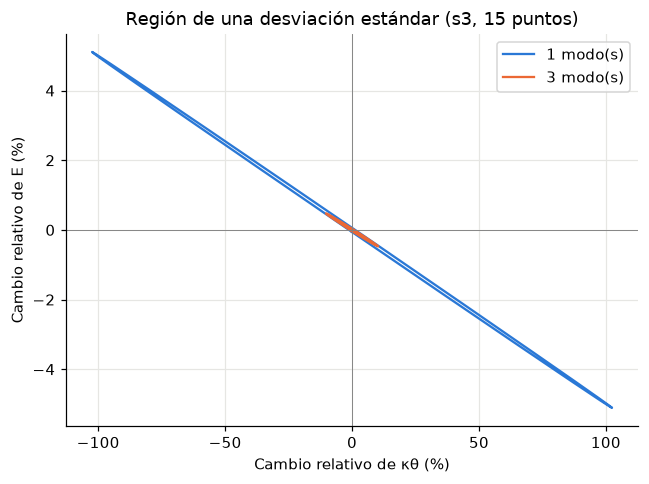

In [7]:
filas_dir = []
covarianzas = {}
for n_modos in (1, 3):
    F = fisher(VIGA, "voladizo", soporte_s3, puntos("uniforme", 15), n_modos=n_modos)
    direcciones = direcciones_fisher(F)
    covarianzas[n_modos] = np.linalg.inv(F)
    for i, nombre in enumerate(("mejor determinada", "peor determinada")):
        a, b = direcciones.vectores[:, i]
        filas_dir.append({
            "Modos": n_modos,
            "Dirección": nombre,
            "Combinación": f"{a:+.3f}·ln E {b:+.3f}·ln κθ",
            "Desviación mínima (%)": 100 * direcciones.desviacion[i],
        })
    print(f"{n_modos} modo(s): número de condición = {direcciones.condicion:.2e}, "
          f"correlación entre ln E y ln κθ = {covarianzas[n_modos][0, 1] / np.sqrt(covarianzas[n_modos][0, 0] * covarianzas[n_modos][1, 1]):+.4f}")
display(pd.DataFrame(filas_dir).round(3))

fig, ax = plt.subplots(figsize=(6, 4.5))
angulo = np.linspace(0, 2 * np.pi, 200)
circulo = np.vstack([np.cos(angulo), np.sin(angulo)])
for n_modos, color in zip((1, 3), COLORES[:2]):
    valores, vectores = np.linalg.eigh(covarianzas[n_modos])
    elipse = 100 * vectores @ (np.sqrt(valores)[:, None] * circulo)
    ax.plot(elipse[1], elipse[0], color=color, label=f"{n_modos} modo(s)")
ax.set(xlabel="Cambio relativo de κθ (%)", ylabel="Cambio relativo de E (%)",
       title="Región de una desviación estándar (s3, 15 puntos)")
ax.axhline(0, color="gray", lw=0.6)
ax.axvline(0, color="gray", lw=0.6)
ax.legend()
fig.tight_layout()
plt.show()

La dirección mejor determinada es casi $\ln E$ con un poco de $\ln \kappa_\theta$: es la combinación que fija la frecuencia, y los datos la acotan a menos de 0.1 %. La peor determinada es casi $\ln \kappa_\theta$ sola: con un modo su incertidumbre es del orden de 100 % y con tres modos baja a cerca de 10 %. Las dos estimaciones están casi perfectamente correlacionadas en sentido negativo (las elipses son tan alargadas que parecen líneas): un anclaje más flexible se puede compensar con un $E$ algo mayor. Por eso la cota de $E$ por sí sola (5 % con un modo) es mucho mayor que la de la dirección bien determinada: casi toda la incertidumbre de $E$ viene de no conocer el anclaje. Agregar modos es la forma de romper esa compensación.

## 6. Alcance y conclusión del frente clásico

En el barrido sintético, los cocientes de frecuencias separan cambios en el patrón modal de cambios comunes de escala; la varianza espacial y la correlación describen qué observaciones cambian juntas; Fisher compara la sensibilidad local a la ubicación y al número de modos, y sus direcciones propias muestran que $E$ queda bien acotado solo en combinación con la rigidez del anclaje, que se separa mejor con tres modos; PCA resume las desviaciones de forma respecto a M0. Estas técnicas guían la selección de características para la inversión y la representación de discrepancia.

Los resultados dependen del modelo sintético, de las seis severidades, de los niveles de ruido asumidos por Fisher y de las condiciones del soporte. La correlación con seis niveles es exploratoria y la cota de Fisher es local. El Brazo 1 real solo aporta una frecuencia por viga, de modo que no permite calcular cocientes de modos medidos. Las conclusiones de identificabilidad global deben apoyarse en el análisis conjunto de estructuras y parámetros del proyecto.